<a href="https://colab.research.google.com/github/nagamamo/machine_learning_for_finance/blob/main/4_1_support_vector_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**4.1  サポートベクター分類（SVC）と家計ファイナンス：金融包摂の事例**

　分類・回帰に用いられるサポートベクターマシン（Support Vector Machine: SVM）のうち、本例では「分類」を行うサポートベクター分類（Support Vector Classification: SVC）の事例を示します。SVMは、ウズベキスタン出身でロンドン大学教授のウラジミール・ヴァプニク教授と同僚（当時）のアレクサンドル・レーナ―博士が1963年に線形分類器として発表した手法がその嚆矢と言われています 。その後、この手法は1992年に米カリフォルニア州立大学のボーザー教授（当時）がヴァプニク教授とともに非線形の分類へ拡張し、今日、世界で幅広く用いられています。「分類」「回帰」ともに、SVMは投資家が投資を行うか否かといった意思決定や、画像認証における識別、製造現場での不良品検知など、様々な用途に用いられます。本例では、家計個票データをもとに、金融包摂されている家計、金融包摂されていない家計がどのような要因により「分類」されているかの事例を紹介します。

　まずはじめに、pandas、numpy、matplotlibに加え、sklearnからSVC用のライブラリSVC、データ標準化のためのStandardScaler、訓練データ・テストデータ分割のためのtrain_test_split、適合率判定のためのaccuracy_scoreの4つのライブラリをインポートします。

In [ ]:
#[1]ライブラリのインポート
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC #SVC推計用ライブラリ
from sklearn.preprocessing import StandardScaler #データ標準化ライブラリ
from sklearn.model_selection import train_test_split #データ分割ライブラリ
from sklearn.metrics import accuracy_score #適合率算出ライブラリ

　次にオンラインストレージから、個票データを取得します。第2節の3行目では、この家計のID番号をインデックス化し、4行目でデータを確認するコードが記述されています。

In [ ]:
#[2]データの取得
url = "https://github.com/nagamamo/data/blob/main/10_banked_household.csv?raw=true"#Git-hubからCSVデータの入手
df = pd.read_csv(url)#データフレームの作成
df = df.set_index("id")#idをインデックスへ変換
df.head()

　取得したデータのうち、banked_householdは、普通銀行に口座を開設している家計(=1）と口座を持たない家計(=0)の二値データです。そしてbranch_popは13州＋連邦直轄地区ごとの人口一人当たりの普通銀行店舗数、incomeが各家計の年収（1,000MYR）の自然対数値です。第3節の3行目は、このデータを70％：30％に訓練データとテストデータに分割する指示を与えています。

In [ ]:
#[3]データの定義とデータの分割
X = df[['branch_pop', 'income']]
y = df['banked_household']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

　第4セルでは、フィッティングとカーネル関数の選択を行った上でSVCによる学習を行います。本例では、非線形RBFカーネルを選択します。非線形多項式カーネルを選択する場合は、kernel='rbf'をkernel='poly'に書き換えてください。併せて3行目では正則化パラメターを設定します。

In [ ]:
#[4]SVCカーネル関数の選択と学習
scaler = StandardScaler() #標準化
scaler.fit(X_train) #フィッティング
clf = SVC(kernel='rbf', C=1.0, gamma='scale') #RBFカーネルと正則化パラメターの選択
#clf = SVC(kernel='poly', degree=2, coef0=1, C=1.0) #多項式カーネルと正則化パラメターの選択
clf.fit(scaler.transform(X_train), y_train) #SVCによる学習

　[4]では訓練データを用いてSVCによる学習を行っていますが、[5]では併せてテストデータを用いてSVCによる学習を行います。

In [ ]:
#[5]テストデータによる学習と予測値の算出
y_pred = clf.predict(scaler.transform(X_test))

　最後に訓練データとテストデータを用いて算出したそれぞれの予測値の適合率を算出します。

In [ ]:
#[6]適合率の算出
accuracy_score(y_test,y_pred) #適合率の算出

0.8696770505858816

　上記の適合率の予測結果をmatplotlibに可視化します。RBFカーネル関数により算出した境界の内側に存在する家計は、所得が低く、一人当たり銀行店舗数が少ない地域の家計であることが視覚的にも確認できます。

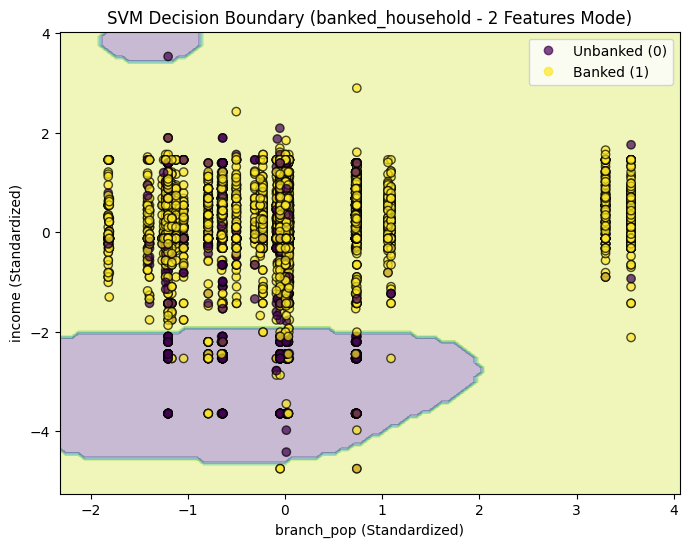

In [ ]:
#[7]可視化
X_train_scaled = scaler.transform(X_train) #2次元変数の標準化
x_min, x_max = X_train_scaled[:, 0].min() - 0.5, X_train_scaled[:, 0].max() + 0.5
y_min, y_max = X_train_scaled[:, 1].min() - 0.5, X_train_scaled[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))
grid_data = np.c_[xx.ravel(), yy.ravel()] #2列のデータを作成
Z = clf.predict(grid_data) #予測値Zの算出
Z = Z.reshape(xx.shape)
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')
scatter = plt.scatter(X_train_scaled[:, 0], X_train_scaled[:, 1], c=y_train, cmap='viridis', edgecolor='k', alpha=0.7) #境界の描画
plt.xlabel("branch_pop (Standardized)") #横軸ラベル
plt.ylabel("income (Standardized)") #縦軸ラベル
plt.title("SVM Decision Boundary (banked_household - 2 Features Mode)")
handles, labels = scatter.legend_elements() #凡例の追加
plt.legend(handles, ['Unbanked (0)', 'Banked (1)'])
plt.show()